# Part II: Feature Engineering and Scaling
Upload `train.csv` and `test.csv` to the Colab session (or change `DATA_DIR`).

### Setup

In [1]:
import time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor
from sklearn.metrics import r2_score
from sklearn.exceptions import ConvergenceWarning

SEED = 0
np.random.seed(SEED)
random.seed(SEED)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

DATA_DIR = "./"
TARGET = "rentals"
WEATHER = ["temperature", "precipitation", "humidity", "wind_speed"]

train = pd.read_csv(DATA_DIR + "train.csv", parse_dates=["datetime"], encoding="utf-8-sig")
test = pd.read_csv(DATA_DIR + "test.csv", parse_dates=["datetime"], encoding="utf-8-sig")
print(train.shape, test.shape)
print(train.head())


def add_features(df):
    df = df.copy()
    df["hour"] = df["datetime"].dt.hour
    df["weekday"] = df["datetime"].dt.dayofweek
    df["is_weekend"] = (df["weekday"] >= 5).astype(int)
    df["workday"] = ((df["is_weekend"] == 0) & (df["is_holiday"] == 0)).astype(int)
    df["rain"] = (df["precipitation"] > 0).astype(int)
    period = np.select([df["hour"].between(7, 9), df["hour"].between(17, 19)], ["am", "pm"], "off")
    df["period_wd"] = pd.Series(period, index=df.index) + "_" + df["workday"].astype(str)
    df["hour_wd"] = df["hour"].astype(str) + "_" + df["workday"].astype(str)
    df["station_cat"] = df["station"].astype(str)
    df["hour_cat"] = df["hour"].astype(str)
    df["weekday_cat"] = df["weekday"].astype(str)
    df["station_period"] = df["station_cat"] + "_" + df["period_wd"]
    df["station_hour_wd"] = df["station_cat"] + "_" + df["hour_wd"]
    df["rain_peak"] = df["rain"] * (period != "off").astype(int) * df["workday"]
    return df


train = add_features(train)
is_val = train["datetime"].dt.month == 5  # May = validation
tr, va = train[~is_val].reset_index(drop=True), train[is_val].reset_index(drop=True)
y_tr, y_va = tr[TARGET].values, va[TARGET].values
print(f"train: {len(tr)} rows, valid: {len(va)} rows")


def make_scaler(name):
    return {"none": "passthrough", "standard": StandardScaler(),
            "minmax": MinMaxScaler(), "robust": RobustScaler()}[name]


def make_model(num, cat, reg, scaler="standard", log=True, dense=False):
    trans = []
    if num:
        trans.append(("num", make_scaler(scaler), num))
    if cat:
        trans.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat))
    pipe = Pipeline([("pre", ColumnTransformer(trans, sparse_threshold=0.0 if dense else 0.3)),
                     ("reg", reg)])
    if log:
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p,
                                          inverse_func=np.expm1, check_inverse=False)
    return pipe


def safe_rmse(y, p):
    return float(np.sqrt(np.mean((y - p) ** 2))) if np.all(np.isfinite(p)) else np.inf


def safe_r2(y, p):
    return float(r2_score(y, p)) if np.all(np.isfinite(p)) else -np.inf


def evaluate(model):
    model.fit(tr, y_tr)
    with np.errstate(all="ignore"):
        ptr = np.clip(model.predict(tr), 0, None)
        pva = np.clip(model.predict(va), 0, None)
    pipe = model.regressor_ if isinstance(model, TransformedTargetRegressor) else model
    reg = pipe.named_steps["reg"]
    return {"n_features": pipe[:-1].transform(va.iloc[:1]).shape[1],
            "train_RMSE": safe_rmse(y_tr, ptr), "train_R2": safe_r2(y_tr, ptr),
            "val_RMSE": safe_rmse(y_va, pva), "val_R2": safe_r2(y_va, pva),
            "n_iter": getattr(reg, "n_iter_", None)}

(108720, 11) (21600, 10)
   id   datetime        station district  capacity  is_holiday  temperature  precipitation  humidity  wind_speed  rentals
0   0 2026-01-01         中華桂林路口      萬華區        34           1         16.7            0.0        91        5.76        2
1   1 2026-01-01          大稻埕碼頭      大同區        52           1         16.7            0.0        91        5.76       14
2   2 2026-01-01        捷運中山國中站      中山區        61           1         16.7            0.0        91        5.76       23
3   3 2026-01-01  捷運信義安和站(4號出口)      大安區        49           1         16.7            0.0        91        5.76        0
4   4 2026-01-01    捷運公館站(2號出口)      大安區        99           1         16.7            0.0        91        5.76       18
train: 86400 rows, valid: 22320 rows


### Part II(a): Exploration

count    108720.000000
mean         27.237831
std          28.027379
min           0.000000
25%           4.000000
50%          21.000000
75%          40.000000
max         257.000000
Name: rentals, dtype: float64
share of zero-rental hours: 0.098


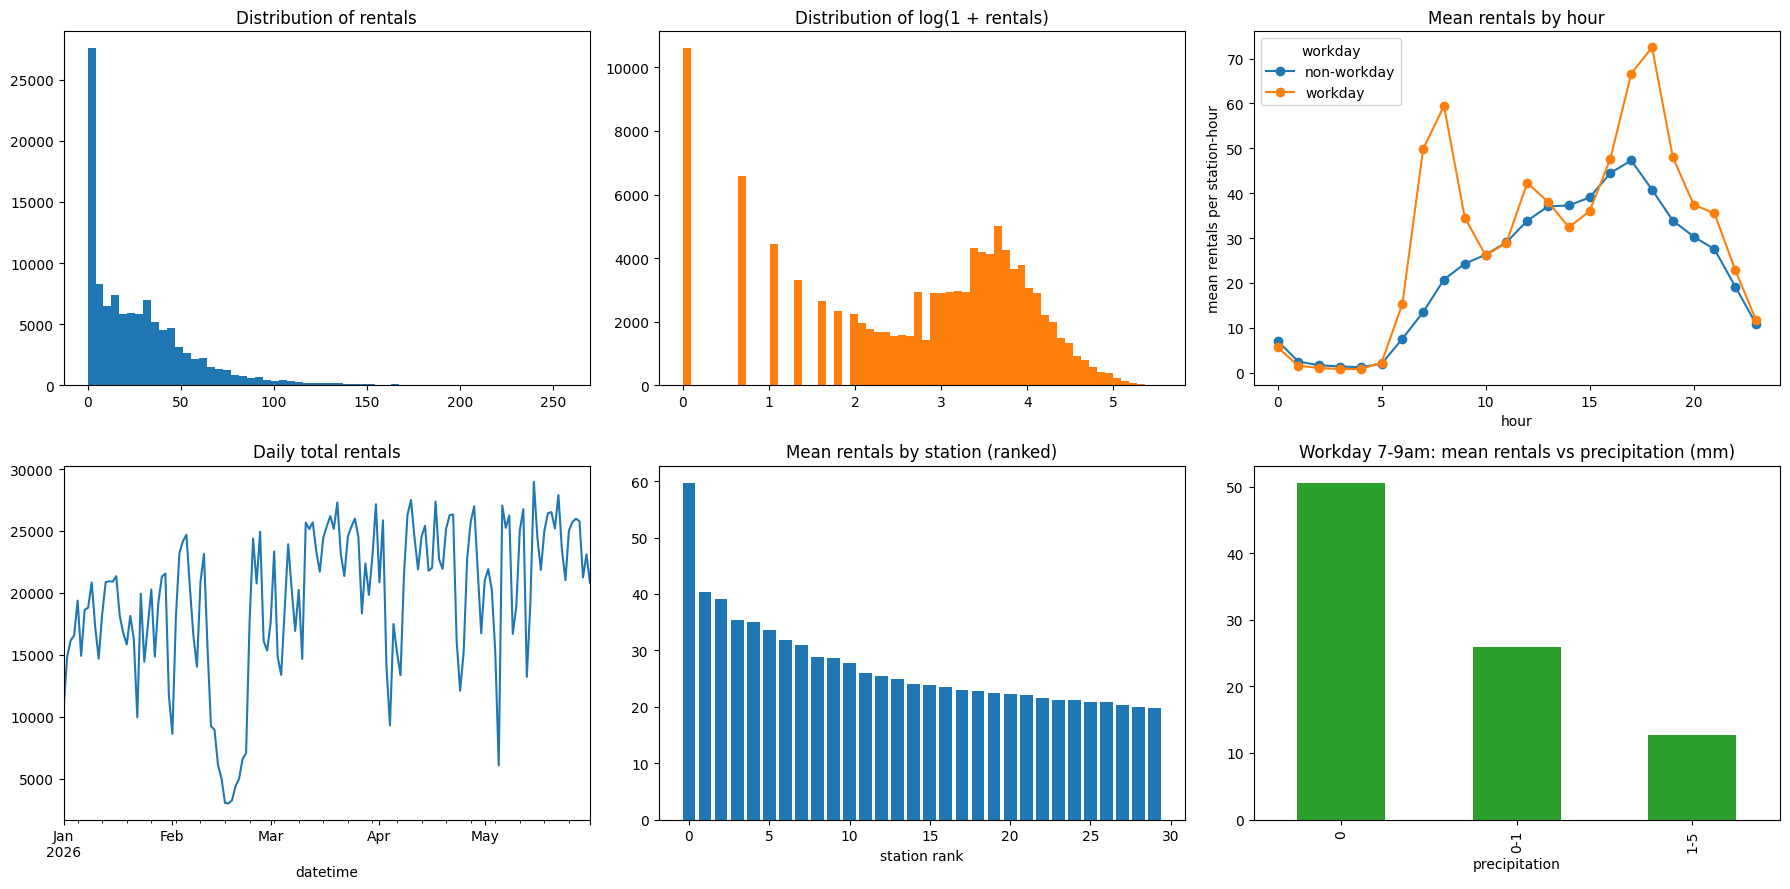

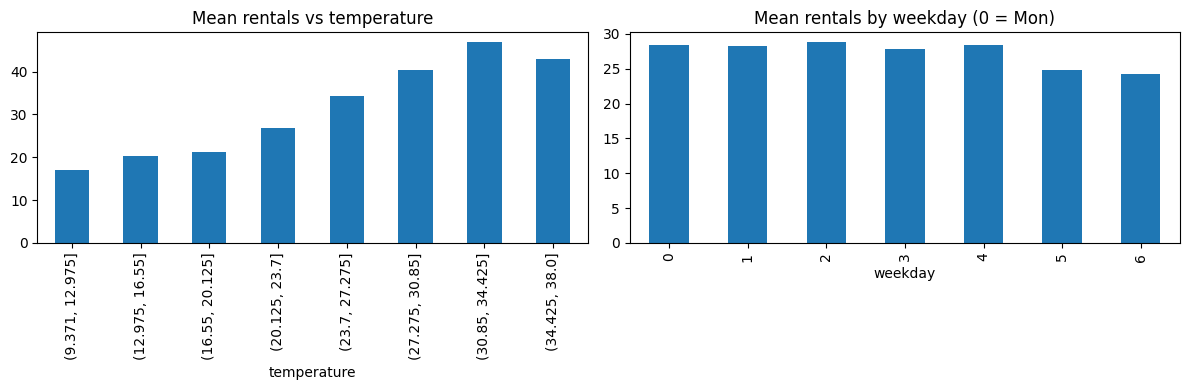

Station ranking:
                station    rentals
rank                              
0           捷運公館站(2號出口)  59.744481
1               捷運科技大樓站  40.379967
2           捷運圓山站(1號出口)  39.051325
3           捷運東門站(5號出口)  35.424393
4               捷運中山國中站  35.039183
5         捷運芝山站(2號出口)_1  33.617826
6         捷運信義安和站(4號出口)  31.801876
7           捷運永春站(2號出口)  30.974614
8                捷運六張犁站  28.774558
9           捷運公館站(3號出口)  28.645419
10                大稻埕碼頭  27.672185
11        捷運南京三民站(1號出口)  25.899007
12          臺大第一活動中心西南側  25.461093
13         捷運行天宮站(3號出口)  24.866998
14          捷運大安站(4號出口)  24.110375
15                 松山車站  23.870033
16              松仁路95巷口  23.443709
17          捷運象山站(2號出口)  23.047185
18       捷運國父紀念館站(2號出口)  22.846854
19          臺北市立圖書館(總館)  22.371137
20          捷運芝山站(1號出口)  22.279525
21               中華桂林路口  22.051600
22          捷運古亭站(6號出口)  21.494757
23          臺灣師範大學(圖書館)  21.246413
24    捷運台北101/世貿站(2號出口)  21.164735
25               林森長春路口  20.857892
26 

In [2]:
print(train[TARGET].describe())
print("share of zero-rental hours:", round((train[TARGET] == 0).mean(), 3))

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes[0, 0].hist(train[TARGET], bins=60)
axes[0, 0].set_title("Distribution of rentals")
axes[0, 1].hist(np.log1p(train[TARGET]), bins=60, color="tab:orange")
axes[0, 1].set_title("Distribution of log(1 + rentals)")

prof = train.groupby(["workday", "hour"])[TARGET].mean().unstack(0)
prof = prof.rename(columns={0: "non-workday", 1: "workday"})
prof.plot(ax=axes[0, 2], marker="o")
axes[0, 2].set_title("Mean rentals by hour")
axes[0, 2].set_ylabel("mean rentals per station-hour")

daily = train.set_index("datetime")[TARGET].resample("D").sum()
daily.plot(ax=axes[1, 0])
axes[1, 0].set_title("Daily total rentals")

st = train.groupby("station")[TARGET].mean().sort_values(ascending=False)
axes[1, 1].bar(range(len(st)), st.values)
axes[1, 1].set_title("Mean rentals by station (ranked)")
axes[1, 1].set_xlabel("station rank")

peak = train[(train["workday"] == 1) & train["hour"].between(7, 9)]
bins = pd.cut(peak["precipitation"], [-0.1, 0, 1, 5, 1000], labels=["0", "0-1", "1-5", ">5"])
peak.groupby(bins, observed=True)[TARGET].mean().plot.bar(ax=axes[1, 2], color="tab:green")
axes[1, 2].set_title("Workday 7-9am: mean rentals vs precipitation (mm)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
tb = pd.cut(train["temperature"], 8)
train.groupby(tb, observed=True)[TARGET].mean().plot.bar(ax=axes[0])
axes[0].set_title("Mean rentals vs temperature")
train.groupby("weekday")[TARGET].mean().plot.bar(ax=axes[1])
axes[1].set_title("Mean rentals by weekday (0 = Mon)")
plt.tight_layout()
plt.show()

print("Station ranking:")
print(st.reset_index().rename_axis("rank"))

### Part II(a): Baseline and target transform

In [3]:
S3 = (WEATHER + ["capacity", "rain", "rain_peak"],
      ["hour_cat", "weekday_cat", "station_cat", "hour_wd", "station_period"])
baseline_tbl = pd.DataFrame({
    "Baseline LR, y": evaluate(make_model(WEATHER, [], LinearRegression(), scaler="none", log=False)),
    "Baseline LR, log1p(y)": evaluate(make_model(WEATHER, [], LinearRegression(), scaler="none", log=True)),
    "Rich Ridge, y": evaluate(make_model(*S3, Ridge(alpha=1.0), log=False)),
    "Rich Ridge, log1p(y)": evaluate(make_model(*S3, Ridge(alpha=1.0), log=True)),
}).T
print("\nBaseline / target transform (RMSE on original scale):")
print(baseline_tbl[["train_RMSE", "train_R2", "val_RMSE", "val_R2"]].round(4))

USE_LOG = True


Baseline / target transform (RMSE on original scale):
                       train_RMSE  train_R2  val_RMSE  val_R2
Baseline LR, y            25.0893    0.1440   29.3745  0.0988
Baseline LR, log1p(y)     28.4616   -0.1015   38.1585 -0.5208
Rich Ridge, y             14.5605    0.7117   16.5955  0.7124
Rich Ridge, log1p(y)      14.6424    0.7085   16.2617  0.7238


### Part II(b): Feature engineering

In [4]:
FEATURE_SETS = {
    "S0: weather":
        (WEATHER, []),
    "S1: + hour, weekday, workday, capacity":
        (WEATHER + ["capacity", "workday"], ["hour_cat", "weekday_cat"]),
    "S2: + station, hour x workday, rain":
        (WEATHER + ["capacity", "rain"], ["hour_cat", "weekday_cat", "station_cat", "hour_wd"]),
    "S3: + station x period x workday, rain x peak":
        S3,
    "S4: + station x hour x workday":
        (S3[0], S3[1] + ["station_hour_wd"]),
}
fe_tbl = pd.DataFrame({name: evaluate(make_model(num, cat, Ridge(alpha=1.0), log=USE_LOG))
                       for name, (num, cat) in FEATURE_SETS.items()}).T
print("\nFeature sets (Ridge alpha=1):")
print(fe_tbl[["n_features", "train_RMSE", "val_RMSE", "val_R2"]].round(4))


Feature sets (Ridge alpha=1):
                                               n_features  train_RMSE  val_RMSE  val_R2
S0: weather                                           4.0     28.4615   38.1580 -0.5207
S1: + hour, weekday, workday, capacity               37.0     20.0325   22.2926  0.4810
S2: + station, hour x workday, rain                 115.0     16.6703   18.6233  0.6378
S3: + station x period x workday, rain x peak       296.0     14.6424   16.2617  0.7238
S4: + station x hour x workday                     1736.0     12.3207   13.4316  0.8116


### Part II(c): Feature scaling

In [5]:
SC_NUM, SC_CAT = FEATURE_SETS["S2: + station, hour x workday, rain"]
models_c = {
    "LinearRegression": lambda: LinearRegression(),
    "Ridge (alpha=1000)": lambda: Ridge(alpha=1000.0),
    "SGDRegressor (eta0=0.01)": lambda: SGDRegressor(max_iter=1000, tol=1e-4, eta0=0.01, random_state=SEED),
}
rows = []
for mname, mk in models_c.items():
    for scaler in ["none", "standard", "minmax", "robust"]:
        t0 = time.time()
        r = evaluate(make_model(SC_NUM, SC_CAT, mk(), scaler=scaler, log=USE_LOG, dense=True))
        rows.append({"model": mname, "scaler": scaler, "val_RMSE": r["val_RMSE"],
                     "val_R2": r["val_R2"], "GD_iterations": r["n_iter"],
                     "fit_sec": round(time.time() - t0, 1)})
sc_tbl = pd.DataFrame(rows)
print("\nScaling comparison (inf = diverged):")
print(sc_tbl.round(4).to_string(index=False))
print(sc_tbl.pivot(index="model", columns="scaler", values="val_RMSE").round(4))


Scaling comparison (inf = diverged):
                   model   scaler  val_RMSE  val_R2  GD_iterations  fit_sec
        LinearRegression     none   18.6237  0.6377            NaN      0.9
        LinearRegression standard   18.6237  0.6377            NaN      0.9
        LinearRegression   minmax   18.6237  0.6377            NaN      0.9
        LinearRegression   robust   18.6237  0.6377            NaN      0.9
      Ridge (alpha=1000)     none   20.4590  0.5628            NaN      0.6
      Ridge (alpha=1000) standard   20.3613  0.5670            NaN      0.6
      Ridge (alpha=1000)   minmax   20.6805  0.5533            NaN      0.6
      Ridge (alpha=1000)   robust   20.3923  0.5657            NaN      0.7
SGDRegressor (eta0=0.01)     none       inf    -inf          231.0     11.5
SGDRegressor (eta0=0.01) standard   18.6844  0.6354           18.0      1.3
SGDRegressor (eta0=0.01)   minmax   18.5749  0.6396           17.0      1.3
SGDRegressor (eta0=0.01)   robust   18.6107  0.638

# Part III: Learning Curves and Forecasting
Upload `train.csv`, `test.csv`, `sample_submission.csv` to the Colab session (or change `DATA_DIR`).

### Setup

In [1]:
import random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import learning_curve, KFold
from sklearn.metrics import r2_score
from sklearn.exceptions import ConvergenceWarning

SEED = 0
np.random.seed(SEED)
random.seed(SEED)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)

DATA_DIR = "./"
TARGET = "rentals"
WEATHER = ["temperature", "precipitation", "humidity", "wind_speed"]
USE_LOG = True

train = pd.read_csv(DATA_DIR + "train.csv", parse_dates=["datetime"], encoding="utf-8-sig")
test = pd.read_csv(DATA_DIR + "test.csv", parse_dates=["datetime"], encoding="utf-8-sig")
sample = pd.read_csv(DATA_DIR + "sample_submission.csv")


def add_features(df):
    df = df.copy()
    df["hour"] = df["datetime"].dt.hour
    df["weekday"] = df["datetime"].dt.dayofweek
    df["is_weekend"] = (df["weekday"] >= 5).astype(int)
    df["workday"] = ((df["is_weekend"] == 0) & (df["is_holiday"] == 0)).astype(int)
    df["rain"] = (df["precipitation"] > 0).astype(int)
    period = np.select([df["hour"].between(7, 9), df["hour"].between(17, 19)], ["am", "pm"], "off")
    df["period_wd"] = pd.Series(period, index=df.index) + "_" + df["workday"].astype(str)
    df["hour_wd"] = df["hour"].astype(str) + "_" + df["workday"].astype(str)
    df["station_cat"] = df["station"].astype(str)
    df["hour_cat"] = df["hour"].astype(str)
    df["weekday_cat"] = df["weekday"].astype(str)
    df["station_period"] = df["station_cat"] + "_" + df["period_wd"]
    df["station_hour_wd"] = df["station_cat"] + "_" + df["hour_wd"]
    df["rain_peak"] = df["rain"] * (period != "off").astype(int) * df["workday"]
    return df


train = add_features(train)
test = add_features(test)
is_val = train["datetime"].dt.month == 5
tr, va = train[~is_val].reset_index(drop=True), train[is_val].reset_index(drop=True)
y_tr, y_va = tr[TARGET].values, va[TARGET].values


def make_model(num, cat, reg, log=USE_LOG, poly=None):
    trans = []
    if num:
        trans.append(("num", StandardScaler(), num))
    if cat:
        trans.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat))
    steps = [("pre", ColumnTransformer(trans))]
    if poly:
        steps.append(("poly", PolynomialFeatures(degree=poly, include_bias=False)))
    steps.append(("reg", reg))
    pipe = Pipeline(steps)
    if log:
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p,
                                          inverse_func=np.expm1, check_inverse=False)
    return pipe


def safe_rmse(y, p):
    return float(np.sqrt(np.mean((y - p) ** 2))) if np.all(np.isfinite(p)) else np.inf


def evaluate(model):
    model.fit(tr, y_tr)
    with np.errstate(all="ignore"):
        ptr = np.clip(model.predict(tr), 0, None)
        pva = np.clip(model.predict(va), 0, None)
    pipe = model.regressor_ if isinstance(model, TransformedTargetRegressor) else model
    return {"n_features": pipe[:-1].transform(va.iloc[:1]).shape[1],
            "train_RMSE": safe_rmse(y_tr, ptr),
            "val_RMSE": safe_rmse(y_va, pva),
            "val_R2": float(r2_score(y_va, pva)) if np.all(np.isfinite(pva)) else -np.inf}


S3 = (WEATHER + ["capacity", "rain", "rain_peak"],
      ["hour_cat", "weekday_cat", "station_cat", "hour_wd", "station_period"])
FEATURE_SETS = {
    "S2": (WEATHER + ["capacity", "rain"], ["hour_cat", "weekday_cat", "station_cat", "hour_wd"]),
    "S3": S3,
    "S4": (S3[0], S3[1] + ["station_hour_wd"]),
}

# Use the provided plot_learning_curve helper instead if your starter notebook defines one.
LC_X = train.reset_index(drop=True)
LC_y = LC_X[TARGET].values
CV = KFold(n_splits=5, shuffle=False)
SIZES = np.linspace(0.05, 1.0, 8)


def plot_lc(est, ax, title, log_y=False):
    sizes, tr_s, va_s = learning_curve(est, LC_X, LC_y, cv=CV, train_sizes=SIZES,
                                       scoring="neg_root_mean_squared_error",
                                       n_jobs=-1, shuffle=False)
    trm, vam = -np.nanmean(tr_s, axis=1), -np.nanmean(va_s, axis=1)
    ax.plot(sizes, trm, "o-", label="training RMSE")
    ax.plot(sizes, vam, "o-", label="cross-validation RMSE")
    ax.fill_between(sizes, trm - np.nanstd(tr_s, 1), trm + np.nanstd(tr_s, 1), alpha=0.15)
    ax.fill_between(sizes, vam - np.nanstd(va_s, 1), vam + np.nanstd(va_s, 1), alpha=0.15)
    ax.set_title(title)
    ax.set_xlabel("number of training examples")
    ax.set_ylabel("RMSE")
    if log_y:
        ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()
    print(f"{title}: train={trm[-1]:.3f}, CV={vam[-1]:.3f}, gap={vam[-1] - trm[-1]:.3f}")

### Part III(a): Diagnosis

Model A: weather + numeric hour (LR): train=27.006, CV=27.629, gap=0.623
Model B: degree-2 polynomial (LR), log y-axis: train=10.635, CV=172.019, gap=161.385


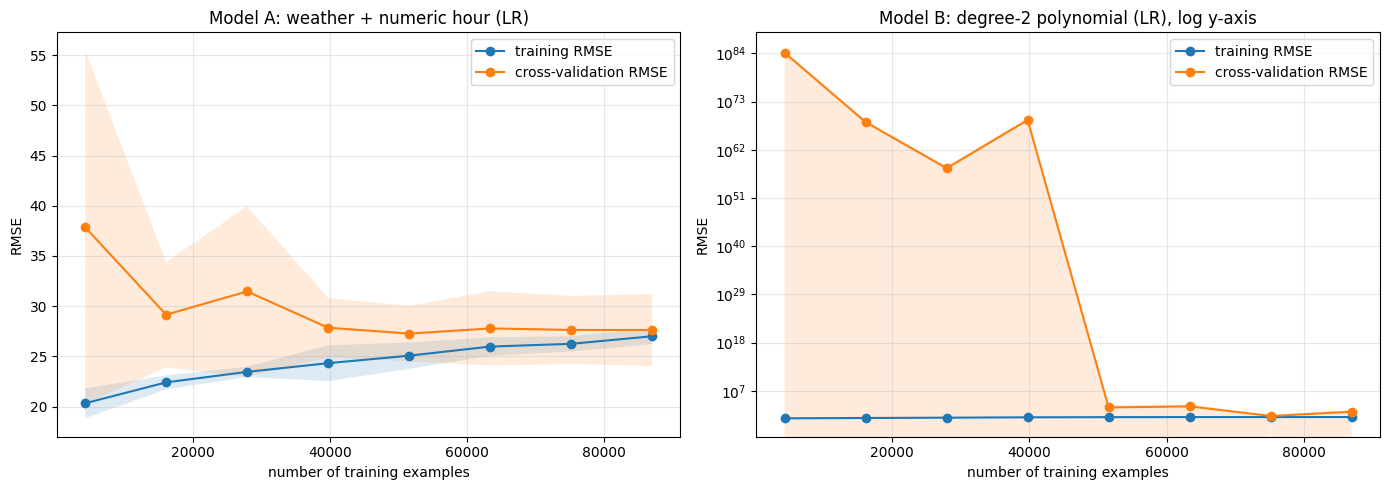

         n_features  train_RMSE  val_RMSE    val_R2
Model A         5.0     26.1817   31.8916   -0.0623
Model B      4094.0     10.8422  337.6152 -118.0480


In [2]:
B_CAT = ["station_cat", "hour_wd", "weekday_cat"]


def model_A():
    # weather + hour as a single numeric column
    return make_model(WEATHER + ["hour"], [], LinearRegression())


def model_B(reg=None):
    # degree-2 polynomial on one-hot + weather, no regularization
    return make_model(WEATHER, B_CAT, reg if reg is not None else LinearRegression(), poly=2)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_lc(model_A(), axes[0], "Model A: weather + numeric hour (LR)")
plot_lc(model_B(), axes[1], "Model B: degree-2 polynomial (LR), log y-axis", log_y=True)
plt.tight_layout()
plt.show()

print(pd.DataFrame({"Model A": evaluate(model_A()), "Model B": evaluate(model_B())}).T.round(4))

### Part III(b): Remedies

   alpha  train_RMSE  val_RMSE
0      1     10.8604  297.7630
1     10     11.1302  155.0282
2    100     13.3050   64.3167
3   1000     17.3483   21.2752
4   3000     20.4577   20.5244
5  10000     24.0536   24.5146
6  30000     26.3503   27.8278
best alpha for Model B: 3000.0
Model A + richer features (S3, Ridge): train=14.692, CV=15.739, gap=1.046
Model B + Ridge (alpha=3000): train=20.897, CV=21.354, gap=0.457


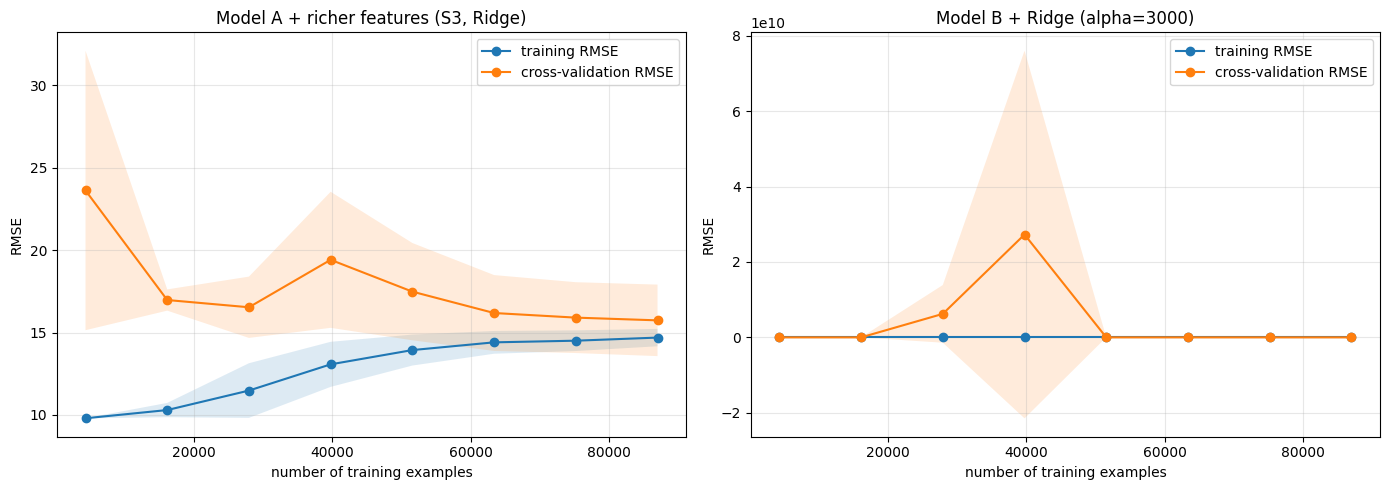

               n_features  train_RMSE  val_RMSE  val_R2
Model A fixed       296.0     14.6424   16.2617  0.7238
Model B fixed      4094.0     20.4577   20.5244  0.5600


In [3]:
alpha_tbl = pd.DataFrame([{"alpha": a, **evaluate(model_B(Ridge(alpha=a)))}
                          for a in [1, 10, 100, 1000, 3000, 10000, 30000]])
print(alpha_tbl[["alpha", "train_RMSE", "val_RMSE"]].round(4))
BEST_ALPHA = float(alpha_tbl.loc[alpha_tbl["val_RMSE"].idxmin(), "alpha"])
print("best alpha for Model B:", BEST_ALPHA)


def model_A_fixed():
    return make_model(*FEATURE_SETS["S3"], Ridge(alpha=1.0))


def model_B_fixed():
    return model_B(Ridge(alpha=BEST_ALPHA))


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_lc(model_A_fixed(), axes[0], "Model A + richer features (S3, Ridge)")
plot_lc(model_B_fixed(), axes[1], f"Model B + Ridge (alpha={BEST_ALPHA:g})")
plt.tight_layout()
plt.show()

print(pd.DataFrame({"Model A fixed": evaluate(model_A_fixed()),
                    "Model B fixed": evaluate(model_B_fixed())}).T.round(4))

### Part III(c): Final model and submission

In [4]:
candidates = {}
for name, (num, cat) in FEATURE_SETS.items():
    for a in [0.3, 1, 3, 10]:
        candidates[f"{name} Ridge(alpha={a})"] = (
            lambda n=num, c=cat, a=a: make_model(n, c, Ridge(alpha=a)))
candidates[f"Model B Ridge(alpha={BEST_ALPHA:g})"] = model_B_fixed

cand_tbl = pd.DataFrame({k: evaluate(f()) for k, f in candidates.items()}).T
cand_tbl = cand_tbl.sort_values("val_RMSE")
print(cand_tbl.round(4))
BEST = cand_tbl.index[0]
print("Selected:", BEST, "| validation RMSE =", round(cand_tbl.loc[BEST, "val_RMSE"], 4))

final = candidates[BEST]()
final.fit(train, train[TARGET].values)  # retrain on all of train.csv
test_pred = np.clip(final.predict(test), 0, None)

target_col = [c for c in sample.columns if c != "id"][0]
sub = sample[["id"]].merge(pd.DataFrame({"id": test["id"], target_col: test_pred}), on="id", how="left")
assert sub[target_col].notna().all() and len(sub) == len(sample)
sub.to_csv("submission.csv", index=False)
print(sub.head())
print("saved submission.csv", sub.shape)

try:
    from google.colab import files
    files.download("submission.csv")
except Exception:
    pass

                           n_features  train_RMSE  val_RMSE  val_R2
S4 Ridge(alpha=0.3)            1736.0     12.3081   13.4248  0.8118
S4 Ridge(alpha=1)              1736.0     12.3207   13.4316  0.8116
S4 Ridge(alpha=3)              1736.0     12.3585   13.4558  0.8109
S4 Ridge(alpha=10)             1736.0     12.5028   13.5743  0.8076
S3 Ridge(alpha=0.3)             296.0     14.6393   16.2590  0.7239
S3 Ridge(alpha=1)               296.0     14.6424   16.2617  0.7238
S3 Ridge(alpha=3)               296.0     14.6512   16.2694  0.7235
S3 Ridge(alpha=10)              296.0     14.6838   16.2978  0.7226
S2 Ridge(alpha=0.3)             115.0     16.6688   18.6229  0.6378
S2 Ridge(alpha=1)               115.0     16.6703   18.6233  0.6378
S2 Ridge(alpha=3)               115.0     16.6746   18.6245  0.6377
S2 Ridge(alpha=10)              115.0     16.6900   18.6289  0.6375
Model B Ridge(alpha=3000)      4094.0     20.4577   20.5244  0.5600
Selected: S4 Ridge(alpha=0.3) | validation RMSE 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>